#### Inspect the Available Transaction Dataset

Load a small sample of the enriched transaction dataset to inspect its columns and data types. This helps identify the fields available for constructing household-level purchasing features without loading the entire dataset unnecessarily.

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import os

# Define the processed dataset path
data_path = "../data/processed/transactions_enriched.csv"

# Check whether the dataset exists
print("Dataset exists:", os.path.exists(data_path))

# Load a small sample for inspection
transactions_sample = pd.read_csv(data_path, nrows=5)

# Inspect columns and data types
print("\nAvailable columns:")
print(transactions_sample.columns.tolist())

print("\nData types:")
display(transactions_sample.dtypes.to_frame("Data Type"))

print("\nSample records:")
display(transactions_sample)

Dataset exists: True

Available columns:
['household_key', 'BASKET_ID', 'DAY', 'PRODUCT_ID', 'QUANTITY', 'SALES_VALUE', 'STORE_ID', 'RETAIL_DISC', 'TRANS_TIME', 'WEEK_NO', 'COUPON_DISC', 'COUPON_MATCH_DISC', 'display_values', 'mailer_values', 'promotion_records', 'retail_discount_amount', 'coupon_discount_amount', 'coupon_match_discount_amount', 'total_discount', 'estimated_original_value', 'discount_percentage', 'COMMODITY_DESC', 'SUB_COMMODITY_DESC', 'BRAND']

Data types:


,Data Type
household_key,int64
BASKET_ID,int64
DAY,int64
PRODUCT_ID,int64
QUANTITY,int64
SALES_VALUE,float64
STORE_ID,int64
RETAIL_DISC,float64
TRANS_TIME,int64
WEEK_NO,int64



Sample records:


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,...,promotion_records,retail_discount_amount,coupon_discount_amount,coupon_match_discount_amount,total_discount,estimated_original_value,discount_percentage,COMMODITY_DESC,SUB_COMMODITY_DESC,BRAND
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,...,NaN,0.60,-0.0,-0.0,0.60,1.99,30.150754,POTATOES,POTATOES RUSSET (BULK&BAG),Private
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,...,NaN,-0.00,-0.0,-0.0,0.00,0.82,0.000000,ONIONS,ONIONS SWEET (BULK&BAG),National
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,...,NaN,0.30,-0.0,-0.0,0.30,1.29,23.255814,VEGETABLES - ALL OTHERS,CELERY,Private
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,...,NaN,-0.00,-0.0,-0.0,0.00,1.21,0.000000,TROPICAL FRUIT,BANANAS,National
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,...,NaN,0.39,-0.0,-0.0,0.39,1.89,20.634921,ORGANICS FRUIT & VEGETABLES,ORGANIC CARROTS,Private


#### Examine Data Coverage for Household Feature Construction

Load only the columns relevant to household-level feature engineering. Examine the dataset size, number of households, missing values and household coverage. This helps us confirm the available data before deciding which features to construct.

In [2]:
# Select columns needed for household-level features
pca_columns = [
    "household_key",
    "BASKET_ID",
    "PRODUCT_ID",
    "QUANTITY",
    "SALES_VALUE",
    "COMMODITY_DESC",
    "SUB_COMMODITY_DESC",
    "total_discount",
    "discount_percentage",
    "BRAND"
]

# Load the required columns
transactions_pca_source = pd.read_csv(
    data_path,
    usecols=pca_columns
)

# Dataset dimensions
print("Dataset shape:", transactions_pca_source.shape)

# Household coverage
print(
    "Unique households:",
    transactions_pca_source["household_key"].nunique()
)

# Missing values
print("\nMissing values:")
display(
    transactions_pca_source.isnull().sum().to_frame(
        "Missing Values"
    )
)

# Household transaction coverage
household_coverage = (
    transactions_pca_source
    .groupby("household_key")
    .agg(
        transaction_records=("BASKET_ID", "count"),
        unique_baskets=("BASKET_ID", "nunique")
    )
)

print("\nHousehold coverage summary:")
display(household_coverage.describe())

Dataset shape: (2595732, 10)
Unique households: 2500

Missing values:


,Missing Values
household_key,0
BASKET_ID,0
PRODUCT_ID,0
QUANTITY,0
SALES_VALUE,0
total_discount,0
discount_percentage,10172
COMMODITY_DESC,0
SUB_COMMODITY_DESC,0
BRAND,0



Household coverage summary:


,transaction_records,unique_baskets
count,2500.000000,2500.000000
mean,1038.292800,110.593600
std,999.097354,115.669368
min,4.000000,1.000000
25%,325.000000,39.000000
50%,734.000000,79.000000
75%,1454.500000,142.250000
max,6851.000000,1300.000000


#### Retrieve the Original Transaction Value

Load the estimated original transaction value from the enriched dataset. This field helps us investigate why some discount percentages are missing and whether the calculation has an invalid denominator.

In [3]:
# Retrieve the original value alongside the existing data
original_value = pd.read_csv(
    data_path,
    usecols=["estimated_original_value"]
)

transactions_pca_source["estimated_original_value"] = (
    original_value["estimated_original_value"]
)

print("Original value column added.")
print(
    "Missing original values:",
    transactions_pca_source["estimated_original_value"].isna().sum()
)

Original value column added.
Missing original values: 0


#### Examine Transactions with Missing Discount Percentages

Identify records with missing discount percentages and examine their sales value, total discount and estimated original value. Check whether missing percentages are associated with zero or invalid original values.

In [4]:
# Select records with missing discount percentages
missing_discount_data = transactions_pca_source[
    transactions_pca_source["discount_percentage"].isna()
].copy()

print("Records with missing discount percentage:",
      len(missing_discount_data))

# Examine relevant numerical fields
display(
    missing_discount_data[
        [
            "SALES_VALUE",
            "total_discount",
            "estimated_original_value"
        ]
    ].describe()
)

# Check zero and negative original values
print(
    "\nZero original values:",
    (missing_discount_data["estimated_original_value"] == 0).sum()
)

print(
    "Negative original values:",
    (missing_discount_data["estimated_original_value"] < 0).sum()
)

print(
    "Missing original values:",
    missing_discount_data["estimated_original_value"].isna().sum()
)

Records with missing discount percentage: 10172


,SALES_VALUE,total_discount,estimated_original_value
count,1.017200e+04,10172.0,10172.0
mean,1.593517e-18,0.0,0.0
std,3.996413e-17,0.0,0.0
min,0.000000e+00,0.0,0.0
25%,0.000000e+00,0.0,0.0
50%,0.000000e+00,0.0,0.0
75%,0.000000e+00,0.0,0.0
max,1.776357e-15,0.0,0.0



Zero original values: 10172
Negative original values: 0
Missing original values: 0


#### Check Discount Percentage Missingness Across Households

Measure how missing discount percentages are distributed across households. This determines whether the missing records are concentrated among a small number of households or spread across the dataset.

In [5]:
# Calculate missing discount percentage counts per household
missing_by_household = (
    transactions_pca_source
    .assign(
        missing_discount_percentage=
        transactions_pca_source["discount_percentage"].isna()
    )
    .groupby("household_key")
    .agg(
        total_records=("discount_percentage", "size"),
        missing_records=("missing_discount_percentage", "sum")
    )
)

missing_by_household["missing_percentage"] = (
    missing_by_household["missing_records"]
    / missing_by_household["total_records"] * 100
)

print("Households with at least one missing percentage:",
      (missing_by_household["missing_records"] > 0).sum())

print("\nMissing percentage per household:")
display(missing_by_household["missing_percentage"].describe())

print("\nHouseholds with the most missing records:")
display(
    missing_by_household
    .sort_values("missing_records", ascending=False)
    .head(10)
)

Households with at least one missing percentage: 1873

Missing percentage per household:


count    2500.000000
mean        0.428438
std         0.658644
min         0.000000
25%         0.000000
50%         0.271555
75%         0.547762
max        12.500000
Name: missing_percentage, dtype: float64


Households with the most missing records:


,total_records,missing_records,missing_percentage
household_key,,,
1098,3339,89,2.665469
618,2090,69,3.301435
1901,4062,60,1.477105
1907,3479,48,1.379707
1041,2674,45,1.682872
641,4381,44,1.004337
2204,1374,38,2.765648
1653,5347,35,0.654573
378,1523,35,2.298096


#### Define Household-Level Purchasing Features

Select numerical measures that describe household purchasing behaviour: transaction activity, basket activity, spending, purchase quantities, product diversity, multi-unit purchasing and discount usage. These features will form the input for PCA.

In [6]:
# Create basket-level spending first
basket_summary = (
    transactions_pca_source
    .groupby(["household_key", "BASKET_ID"])
    .agg(
        basket_value=("SALES_VALUE", "sum"),
        basket_quantity=("QUANTITY", "sum")
    )
    .reset_index()
)

# Create household-level purchasing features
household_features = (
    transactions_pca_source
    .groupby("household_key")
    .agg(
        transaction_records=("BASKET_ID", "count"),
        unique_baskets=("BASKET_ID", "nunique"),
        unique_products=("PRODUCT_ID", "nunique"),
        unique_categories=("COMMODITY_DESC", "nunique"),
        total_quantity=("QUANTITY", "sum"),
        total_sales=("SALES_VALUE", "sum"),
        average_line_sales=("SALES_VALUE", "mean"),
        average_quantity=("QUANTITY", "mean"),
        multi_unit_share=("QUANTITY", lambda x: (x > 1).mean()),
        total_discount=("total_discount", "sum"),
        discounted_record_share=("total_discount", lambda x: (x > 0).mean()),
        private_brand_share=("BRAND", lambda x: (x == "Private").mean())
    )
)

# Add average basket value
average_basket_value = (
    basket_summary
    .groupby("household_key")["basket_value"]
    .mean()
    .rename("average_basket_value")
)

household_features = household_features.join(average_basket_value)

# Calculate weighted household discount percentage
household_original_value = (
    transactions_pca_source
    .groupby("household_key")["estimated_original_value"]
    .sum()
)

household_features["discount_percentage"] = (
    household_features["total_discount"]
    / household_original_value.replace(0, np.nan)
    * 100
)

# Inspect the resulting feature table
print("Household feature table shape:", household_features.shape)
display(household_features.head())

Household feature table shape: (2500, 14)


,transaction_records,unique_baskets,unique_products,unique_categories,total_quantity,total_sales,average_line_sales,average_quantity,multi_unit_share,total_discount,discounted_record_share,private_brand_share,average_basket_value,discount_percentage
household_key,,,,,,,,,,,,,,
1,1727,86,677,128,1997,4330.16,2.507331,1.156340,0.123335,803.75,0.470759,0.117545,50.350698,15.655709
2,714,45,546,141,834,1954.34,2.737171,1.168067,0.114846,343.99,0.460784,0.235294,43.429778,14.966954
3,922,47,516,110,8540,2653.21,2.877668,9.262473,0.382863,756.15,0.583514,0.187636,56.451277,22.178649
4,301,30,164,63,382,1200.11,3.987076,1.269103,0.186047,118.15,0.431894,0.152824,40.003667,8.962572
5,222,40,199,76,245,779.06,3.509279,1.103604,0.094595,118.33,0.531532,0.216216,19.476500,13.186017


#### Validate Household Feature Construction

Check that each household appears exactly once and that the constructed features contain no missing or infinite values. Review descriptive statistics to identify unusual ranges or distributions before preprocessing.

In [7]:
# Check household uniqueness
print("Number of household rows:", len(household_features))
print("Unique household IDs:", household_features.index.nunique())
print("Duplicate household rows:", household_features.index.duplicated().sum())

# Check missing and infinite values
print("\nMissing values:")
display(household_features.isna().sum().to_frame("Missing Values"))

print("\nInfinite values:")
display(
    pd.Series(
        np.isinf(household_features.select_dtypes(include=np.number)).sum(),
        name="Infinite Values"
    ).to_frame()
)

# Examine feature distributions
print("\nFeature summary:")
display(household_features.describe().T)

Number of household rows: 2500
Unique household IDs: 2500
Duplicate household rows: 0

Missing values:


,Missing Values
transaction_records,0
unique_baskets,0
unique_products,0
unique_categories,0
total_quantity,0
total_sales,0
average_line_sales,0
average_quantity,0
multi_unit_share,0
total_discount,0



Infinite values:


,Infinite Values
transaction_records,0
unique_baskets,0
unique_products,0
unique_categories,0
total_quantity,0
total_sales,0
average_line_sales,0
average_quantity,0
multi_unit_share,0
total_discount,0



Feature summary:


,count,mean,std,min,25%,50%,75%,max
transaction_records,2500.0,1038.292800,999.097354,4.000000,325.000000,734.000000,1454.500000,6.851000e+03
unique_baskets,2500.0,110.593600,115.669368,1.000000,39.000000,79.000000,142.250000,1.300000e+03
unique_products,2500.0,560.587600,435.957889,4.000000,230.750000,455.000000,788.000000,3.159000e+03
unique_categories,2500.0,115.476000,45.889142,3.000000,83.000000,118.000000,150.000000,2.430000e+02
total_quantity,2500.0,104274.248800,244456.075850,5.000000,770.000000,11084.500000,87640.000000,4.479917e+06
total_sales,2500.0,3222.985232,3349.026076,8.170000,970.740000,2157.750000,4413.320000,3.831979e+04
average_line_sales,2500.0,3.144357,0.991179,1.153734,2.582284,3.014814,3.508070,1.772616e+01
average_quantity,2500.0,92.077015,242.583572,0.875000,1.309775,14.949832,115.578377,6.393965e+03
multi_unit_share,2500.0,0.207046,0.084981,0.000000,0.149405,0.194237,0.255611,7.323232e-01
total_discount,2500.0,579.412288,593.605267,0.250000,170.407500,396.275000,779.332500,5.162450e+03


#### Examine Feature Skewness and Extreme Values

Calculate skewness and selected percentiles for each household feature. Identify highly skewed features and unusually large values that may influence PCA. Use these results to decide whether transformations or further investigation are needed.

In [8]:
# Calculate skewness for all household features
feature_skewness = (
    household_features
    .skew()
    .sort_values(ascending=False)
)

print("Feature skewness:")
display(feature_skewness.to_frame("Skewness"))

# Examine important percentiles
feature_percentiles = household_features.quantile(
    [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]
)

print("\nFeature percentiles:")
display(feature_percentiles.T)

Feature skewness:


,Skewness
average_quantity,14.449429
total_quantity,5.795760
average_line_sales,4.602778
unique_baskets,3.374329
total_sales,2.407212
total_discount,2.145891
transaction_records,1.825610
average_basket_value,1.724280
unique_products,1.361064
multi_unit_share,1.094374



Feature percentiles:


,0.00,0.25,0.50,0.75,0.90,0.95,0.99,1.00
transaction_records,4.000000,325.000000,734.000000,1454.500000,2357.200000,3020.250000,4.588450e+03,6.851000e+03
unique_baskets,1.000000,39.000000,79.000000,142.250000,229.100000,321.000000,5.531000e+02,1.300000e+03
unique_products,4.000000,230.750000,455.000000,788.000000,1147.100000,1405.000000,1.973210e+03,3.159000e+03
unique_categories,3.000000,83.000000,118.000000,150.000000,174.000000,188.000000,2.090000e+02,2.430000e+02
total_quantity,5.000000,770.000000,11084.500000,87640.000000,329406.000000,529429.700000,1.090773e+06,4.479917e+06
total_sales,8.170000,970.740000,2157.750000,4413.320000,7448.216000,9754.144500,1.532502e+04,3.831979e+04
average_line_sales,1.153734,2.582284,3.014814,3.508070,4.071698,4.578847,6.242751e+00,1.772616e+01
average_quantity,0.875000,1.309775,14.949832,115.578377,258.945757,364.807005,7.646794e+02,6.393965e+03
multi_unit_share,0.000000,0.149405,0.194237,0.255611,0.313224,0.353409,4.887668e-01,7.323232e-01
total_discount,0.250000,170.407500,396.275000,779.332500,1316.492000,1771.932000,2.733197e+03,5.162450e+03


#### Identify Extreme Household Values

Use the interquartile range (IQR) method to identify potential outliers in each feature. Count the flagged observations without removing them. This helps distinguish genuine high-activity households from values that may require transformation or investigation.

In [9]:
# Calculate IQR-based outlier counts
outlier_summary = []

for column in household_features.columns:

    Q1 = household_features[column].quantile(0.25)
    Q3 = household_features[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (household_features[column] < lower_bound)
        | (household_features[column] > upper_bound)
    )

    outlier_summary.append({
        "Feature": column,
        "Outlier_Count": outliers.sum(),
        "Outlier_Percentage": outliers.mean() * 100,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(
    outlier_summary.sort_values(
        "Outlier_Percentage",
        ascending=False
    )
)

,Feature,Outlier_Count,Outlier_Percentage,Lower_Bound,Upper_Bound
4,total_quantity,359,14.36,-129535.000000,217945.000000
7,average_quantity,214,8.56,-170.093127,286.981279
1,unique_baskets,148,5.92,-115.875000,297.125000
9,total_discount,138,5.52,-742.980000,1692.720000
5,total_sales,127,5.08,-4193.130000,9577.190000
0,transaction_records,110,4.40,-1369.250000,3148.750000
12,average_basket_value,90,3.60,-14.997341,73.872327
6,average_line_sales,87,3.48,1.193604,4.896750
2,unique_products,75,3.00,-605.125000,1623.875000
13,discount_percentage,60,2.40,2.138326,28.429986


#### Examine Correlations Between Household Features

Calculate correlations between numerical household features and visualize them using a heatmap. This identifies strongly related features that may contribute overlapping information to PCA. Correlation will guide feature selection, but we will not automatically remove every correlated feature.

,transaction_records,unique_baskets,unique_products,unique_categories,total_quantity,total_sales,average_line_sales,average_quantity,multi_unit_share,total_discount,discounted_record_share,private_brand_share,average_basket_value,discount_percentage
transaction_records,1.00,0.74,0.95,0.81,0.52,0.95,-0.04,0.04,-0.03,0.90,0.07,-0.02,0.33,-0.04
unique_baskets,0.74,1.00,0.70,0.62,0.50,0.70,-0.02,0.10,-0.02,0.66,0.08,0.04,-0.12,-0.05
unique_products,0.95,0.70,1.00,0.89,0.47,0.90,-0.05,0.02,-0.04,0.88,0.12,-0.01,0.36,-0.01
unique_categories,0.81,0.62,0.89,1.00,0.41,0.78,-0.07,-0.01,-0.08,0.73,0.07,-0.04,0.37,-0.05
total_quantity,0.52,0.50,0.47,0.41,1.00,0.67,0.30,0.46,0.06,0.49,0.07,0.02,0.12,-0.15
total_sales,0.95,0.70,0.90,0.78,0.67,1.00,0.15,0.13,0.04,0.87,0.02,-0.08,0.39,-0.12
average_line_sales,-0.04,-0.02,-0.05,-0.07,0.30,0.15,1.00,0.61,0.35,0.02,-0.14,-0.23,0.20,-0.33
average_quantity,0.04,0.10,0.02,-0.01,0.46,0.13,0.61,1.00,0.17,0.05,0.09,0.10,-0.02,-0.21
multi_unit_share,-0.03,-0.02,-0.04,-0.08,0.06,0.04,0.35,0.17,1.00,0.15,0.26,0.21,0.11,0.30
total_discount,0.90,0.66,0.88,0.73,0.49,0.87,0.02,0.05,0.15,1.00,0.28,0.05,0.32,0.20


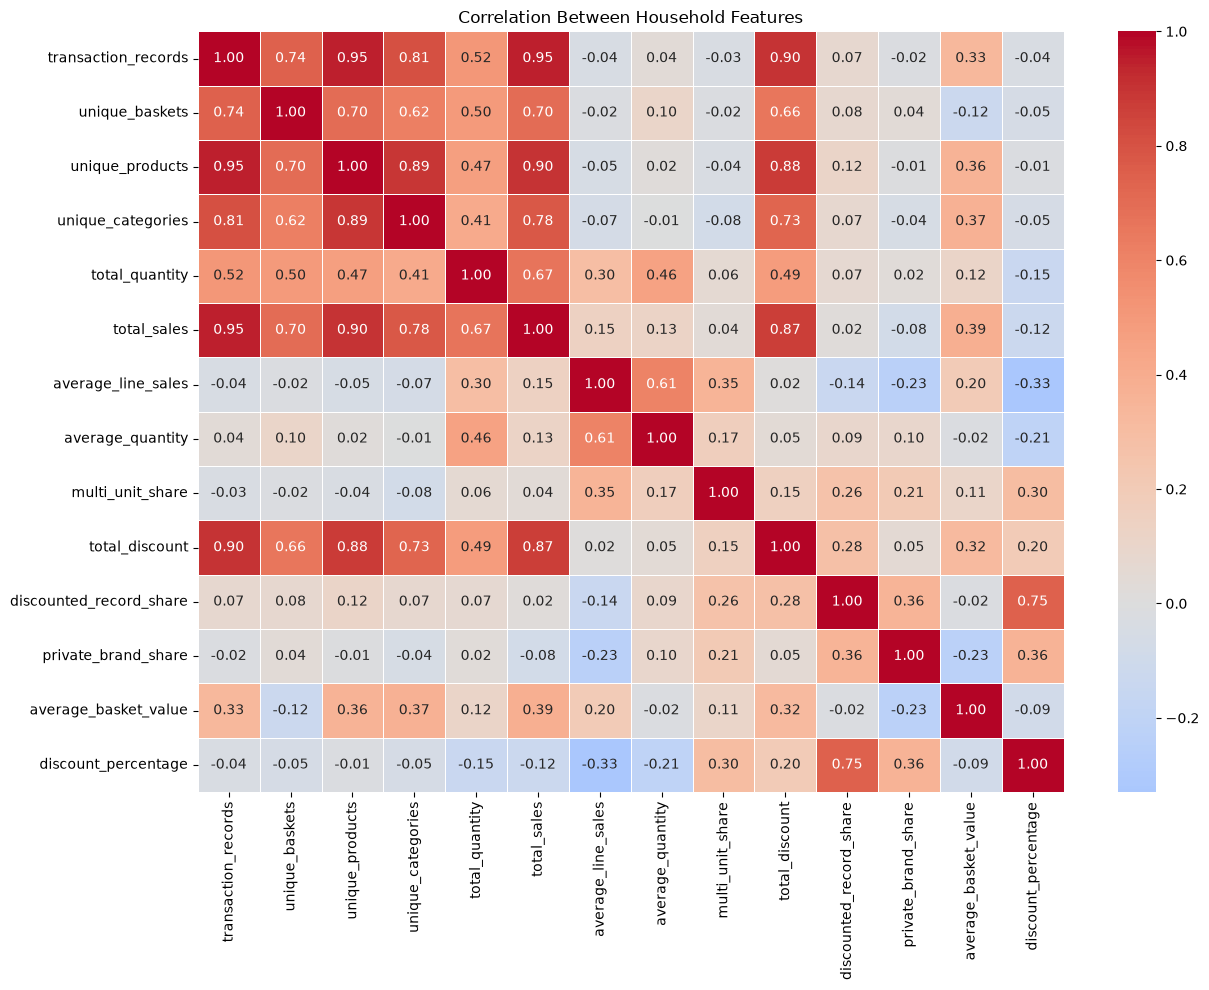

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate feature correlations
feature_correlation = household_features.corr()

# Display the correlation matrix
display(feature_correlation.round(2))

# Visualize correlations
plt.figure(figsize=(13, 10))

sns.heatmap(
    feature_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Between Household Features")
plt.tight_layout()
plt.show()

#### Visualize Distributions of Highly Skewed Features

Plot the distributions of selected highly skewed household features. This helps us understand their long tails and decide whether logarithmic transformations are appropriate before standardization.

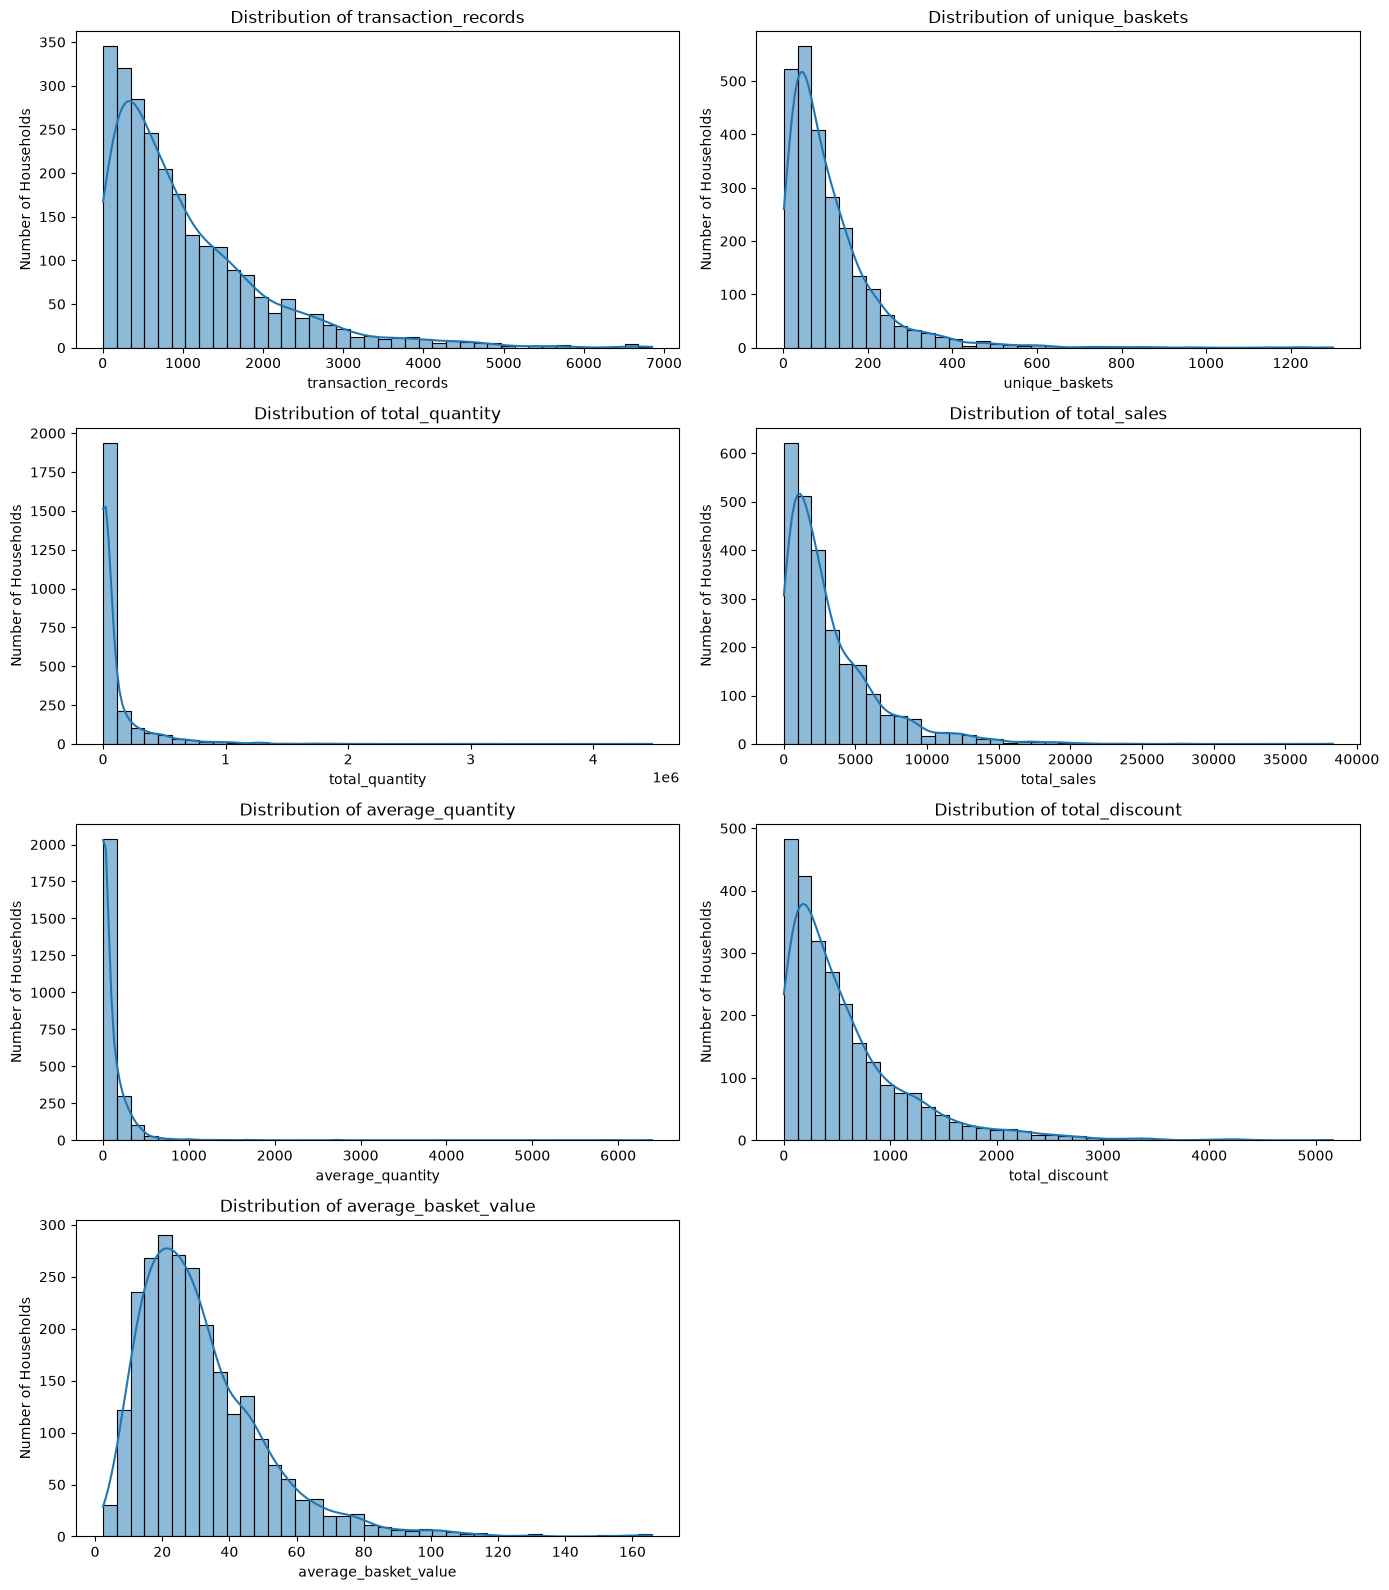

In [11]:
# Select highly skewed positive-valued features
skewed_features = [
    "transaction_records",
    "unique_baskets",
    "total_quantity",
    "total_sales",
    "average_quantity",
    "total_discount",
    "average_basket_value"
]

# Plot distributions in a 4 × 2 grid
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, column in enumerate(skewed_features):

    sns.histplot(
        household_features[column],
        bins=40,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Number of Households")

# Remove the unused subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

#### Feature Transformation Decisions

The skewness analysis identified six features with substantial right skewness. We will apply `log1p` to these features to compress extreme values while preserving zero values.

The remaining features will initially remain unchanged. We will preserve the original DataFrame and validate the transformations by comparing skewness before and after.

In [12]:
# Select features for log transformation
log_features = [
    "unique_baskets",
    "total_quantity",
    "total_sales",
    "average_line_sales",
    "average_quantity",
    "total_discount"
]

# Features to retain without transformation
unchanged_features = [
    "transaction_records",
    "unique_products",
    "unique_categories",
    "multi_unit_share",
    "discounted_record_share",
    "private_brand_share",
    "average_basket_value",
    "discount_percentage"
]

# Display the decisions
transformation_decisions = pd.DataFrame({
    "Feature": log_features + unchanged_features,
    "Decision": (
        ["Apply log1p"] * len(log_features)
        + ["Keep unchanged"] * len(unchanged_features)
    )
})

display(transformation_decisions)

,Feature,Decision
0,unique_baskets,Apply log1p
1,total_quantity,Apply log1p
2,total_sales,Apply log1p
3,average_line_sales,Apply log1p
4,average_quantity,Apply log1p
5,total_discount,Apply log1p
6,transaction_records,Keep unchanged
7,unique_products,Keep unchanged
8,unique_categories,Keep unchanged
9,multi_unit_share,Keep unchanged


#### Apply Transformations and Compare Skewness

We selected six features for log1p transformation based on their observed right skewness.

We will apply the transformation to a copy of the original household features and compare skewness before and after. This will help us check whether the transformation improves the feature distributions before PCA.

In [13]:
# Preserve the original household features
household_features_transformed = household_features.copy()

# Apply log1p to the selected features
for column in log_features:
    household_features_transformed[column] = np.log1p(
        household_features_transformed[column]
    )

# Compare skewness before and after transformation
skewness_comparison = pd.DataFrame({
    "Original Skewness": household_features[log_features].skew(),
    "Transformed Skewness": household_features_transformed[log_features].skew()
})

display(skewness_comparison.round(3))

,Original Skewness,Transformed Skewness
unique_baskets,3.374,-0.401
total_quantity,5.796,-0.057
total_sales,2.407,-0.608
average_line_sales,4.603,1.092
average_quantity,14.449,0.280
total_discount,2.146,-0.788


#### Standardize Features

The household features have different measurement scales, such as transaction counts, monetary values and percentages.

Since PCA is sensitive to differences in feature variance, we will standardize all 14 features using StandardScaler.

This ensures that each feature contributes on a comparable scale. We will retain the standardized data separately.

In [14]:
# Import the standardization method
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Standardize all household features
household_features_scaled = pd.DataFrame(
    scaler.fit_transform(household_features_transformed),
    columns=household_features_transformed.columns,
    index=household_features_transformed.index
)

# Check the resulting feature means and standard deviations
scaling_summary = pd.DataFrame({
    "Mean": household_features_scaled.mean(),
    "Standard Deviation": household_features_scaled.std()
})

display(scaling_summary.round(3))

,Mean,Standard Deviation
transaction_records,0.0,1.0
unique_baskets,-0.0,1.0
unique_products,0.0,1.0
unique_categories,0.0,1.0
total_quantity,-0.0,1.0
total_sales,0.0,1.0
average_line_sales,0.0,1.0
average_quantity,0.0,1.0
multi_unit_share,-0.0,1.0
total_discount,0.0,1.0


#### Apply Principal Component Analysis

Apply PCA to the standardized household features using SVD and calculate the explained variance of each component.

In [15]:
# Import PCA
from sklearn.decomposition import PCA

# Fit PCA using all components
pca = PCA()
household_pca = pca.fit_transform(household_features_scaled)

# Calculate explained variance
pca_variance = pd.DataFrame({
    "Component": [
        f"PC{i+1}" for i in range(len(pca.explained_variance_ratio_))
    ],
    "Explained Variance Ratio": pca.explained_variance_ratio_,
    "Cumulative Explained Variance": np.cumsum(
        pca.explained_variance_ratio_
    )
})

display(pca_variance.round(4))

,Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.4265,0.4265
1,PC2,0.1701,0.5965
2,PC3,0.1269,0.7234
3,PC4,0.0997,0.8231
4,PC5,0.0566,0.8798
5,PC6,0.0483,0.9280
6,PC7,0.0243,0.9523
7,PC8,0.0231,0.9754
8,PC9,0.0128,0.9882
9,PC10,0.0081,0.9963


#### Explained Variance Visualization

Plot the individual and cumulative explained variance to identify the point where additional components provide diminishing returns.

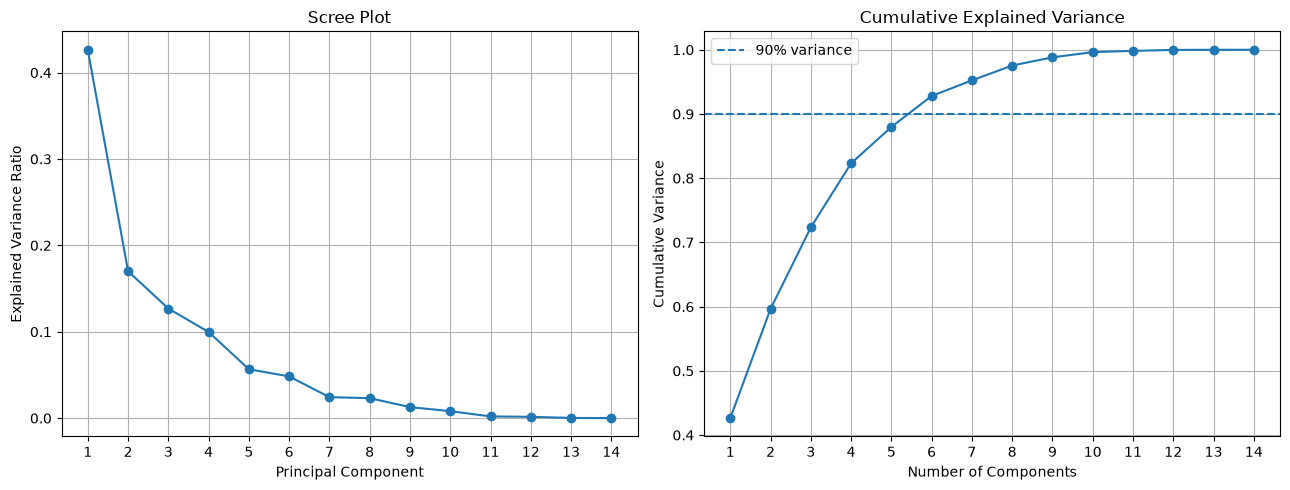

In [16]:
# Plot individual and cumulative explained variance
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Scree plot
axes[0].plot(
    range(1, 15),
    pca.explained_variance_ratio_,
    marker="o"
)
axes[0].set_title("Scree Plot")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance Ratio")
axes[0].set_xticks(range(1, 15))
axes[0].grid(True)

# Cumulative explained variance
axes[1].plot(
    range(1, 15),
    np.cumsum(pca.explained_variance_ratio_),
    marker="o"
)
axes[1].axhline(y=0.90, linestyle="--", label="90% variance")
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of Components")
axes[1].set_ylabel("Cumulative Variance")
axes[1].set_xticks(range(1, 15))
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

#### Retain Six Principal Components

Retain the first six components because they explain 92.80% of the total variance, reducing the feature space from 14 dimensions to 6.

In [17]:
# Retain the first six principal components
n_components = 6

household_pca_reduced = pd.DataFrame(
    household_pca[:, :n_components],
    columns=[f"PC{i+1}" for i in range(n_components)],
    index=household_features.index
)

# Check the resulting dimensions and retained variance
print("Reduced dataset shape:", household_pca_reduced.shape)
print(
    "Retained variance:",
    round(pca.explained_variance_ratio_[:n_components].sum() * 100, 2),
    "%"
)

display(household_pca_reduced.head())

Reduced dataset shape: (2500, 6)
Retained variance: 92.8 %


,PC1,PC2,PC3,PC4,PC5,PC6
household_key,,,,,,
1,0.782396,-0.788374,-2.090637,1.030076,-0.701808,-0.740705
2,-0.502117,-0.579320,-1.684240,0.608605,-0.527336,0.081011
3,0.335612,1.127047,0.725732,2.407996,-0.121402,-0.630529
4,-2.338962,-2.024289,-0.222454,1.086618,0.156293,-0.404849
5,-2.458645,-0.629995,-0.831225,-0.069308,-0.345724,-0.840617


#### Examine Principal Component Loadings

Calculate the loadings of the original 14 features on the six retained principal components and examine their contribution to each component.

In [18]:
# Extract loadings for the six retained components
pca_loadings = pd.DataFrame(
    pca.components_[:n_components].T,
    index=household_features_scaled.columns,
    columns=[f"PC{i+1}" for i in range(n_components)]
)

# Display loadings
display(pca_loadings.round(3))

,PC1,PC2,PC3,PC4,PC5,PC6
transaction_records,0.362,-0.023,-0.169,0.039,0.058,0.084
unique_baskets,0.350,0.029,-0.077,-0.256,0.325,-0.249
unique_products,0.375,-0.009,-0.164,0.054,0.010,0.085
unique_categories,0.382,-0.039,-0.154,0.022,-0.009,0.024
total_quantity,0.314,-0.050,0.367,-0.272,-0.230,0.048
total_sales,0.394,-0.052,-0.054,0.077,0.107,-0.037
average_line_sales,0.037,-0.330,0.498,0.266,0.165,-0.152
average_quantity,0.185,-0.079,0.538,-0.344,-0.319,0.060
multi_unit_share,0.023,0.198,0.443,0.398,0.562,-0.006
total_discount,0.379,0.151,-0.065,0.132,0.045,-0.111


#### Visualize Component Loadings

Plot the feature loadings as a heatmap to compare how the original features contribute to the six retained components.

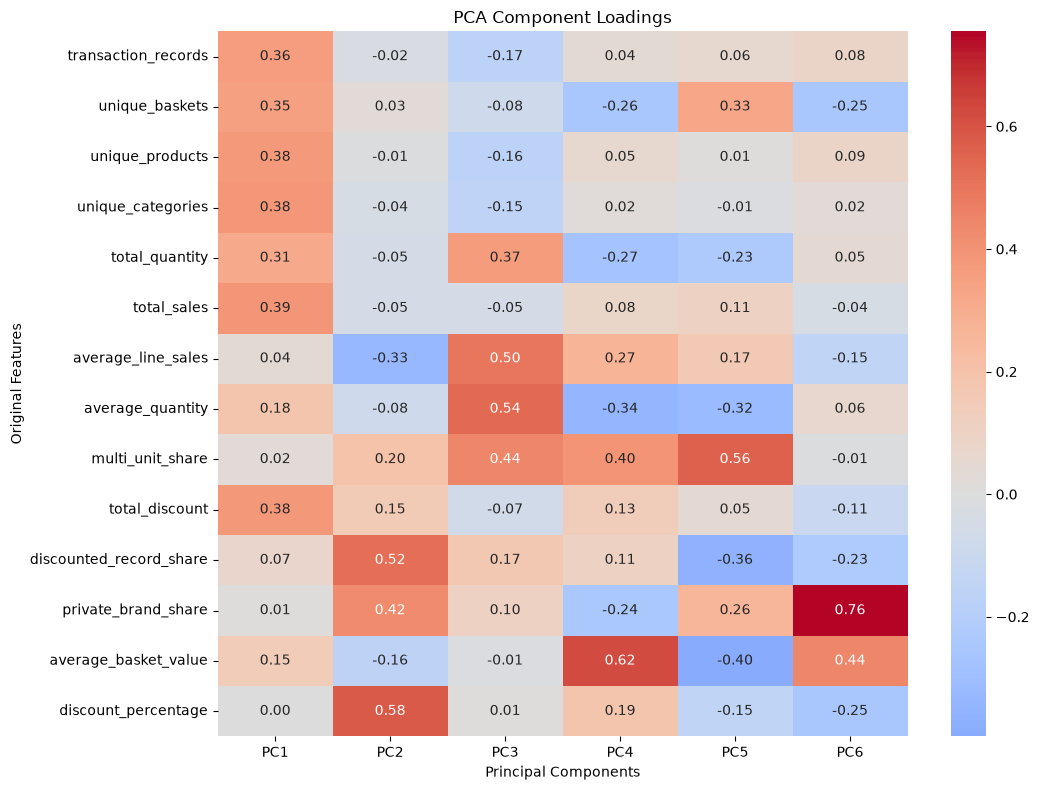

In [19]:
# Plot the component loadings
plt.figure(figsize=(11, 8))

sns.heatmap(
    pca_loadings,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("PCA Component Loadings")
plt.xlabel("Principal Components")
plt.ylabel("Original Features")
plt.tight_layout()
plt.show()

#### Visualize Households in 2D PCA Space

Plot households using PC1 and PC2, with colour representing their discount percentage, to examine how discount behaviour relates to the main patterns of variation.

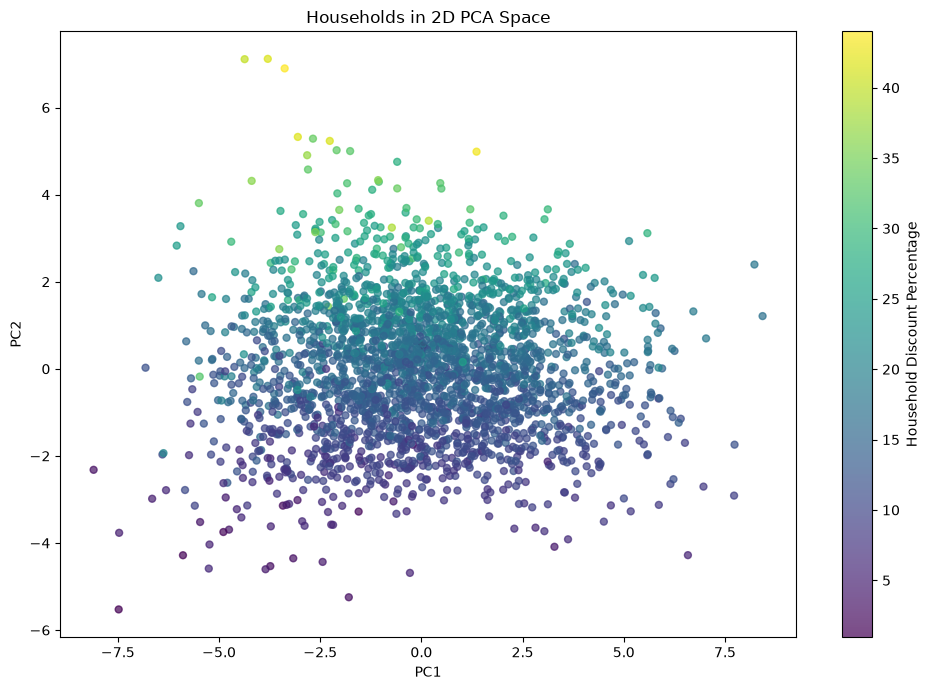

In [20]:
# Plot households in the first two principal components
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    household_pca_reduced["PC1"],
    household_pca_reduced["PC2"],
    c=household_features["discount_percentage"],
    cmap="viridis",
    alpha=0.7,
    s=25
)

plt.colorbar(scatter, label="Household Discount Percentage")
plt.title("Households in 2D PCA Space")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()

#### Evaluate PCA Reconstruction Error

Reconstruct the standardized household features using the six retained components and calculate the reconstruction error to measure information loss.

In [21]:
# Reconstruct using only the first six PCA components
household_reconstructed = (
    household_pca_reduced.values @ pca.components_[:n_components]
    + pca.mean_
)

# Calculate mean squared reconstruction error
reconstruction_error = np.mean(
    (household_features_scaled.values - household_reconstructed) ** 2
)

print("Mean Squared Reconstruction Error:", round(reconstruction_error, 4))

Mean Squared Reconstruction Error: 0.072


#### Feature-wise Reconstruction Error

Calculate the reconstruction error separately for each feature to identify which features retain the most and least information after PCA.

In [22]:
# Calculate mean squared reconstruction error for each feature
feature_reconstruction_error = pd.DataFrame({
    "Feature": household_features_scaled.columns,
    "Reconstruction Error": np.mean(
        (household_features_scaled.values - household_reconstructed) ** 2,
        axis=0
    )
})

feature_reconstruction_error = feature_reconstruction_error.sort_values(
    by="Reconstruction Error",
    ascending=False
)

display(feature_reconstruction_error.round(4))

,Feature,Reconstruction Error
0,transaction_records,0.1574
6,average_line_sales,0.1553
10,discounted_record_share,0.1160
2,unique_products,0.1026
13,discount_percentage,0.0869
8,multi_unit_share,0.0833
3,unique_categories,0.0801
9,total_discount,0.0452
5,total_sales,0.0442
1,unique_baskets,0.0386


#### Save PCA Outputs

Save the reduced household features, explained variance, component loadings and reconstruction errors for use in the subsequent notebooks.

In [23]:
# Create the output directory
import os

pca_output_dir = "../data/processed/dimensionality_reduction"
os.makedirs(pca_output_dir, exist_ok=True)

# Save PCA outputs
household_pca_reduced.to_csv(
    os.path.join(pca_output_dir, "household_pca_features.csv"),
    index=True
)

pca_variance.to_csv(
    os.path.join(pca_output_dir, "pca_explained_variance.csv"),
    index=False
)

pca_loadings.to_csv(
    os.path.join(pca_output_dir, "pca_component_loadings.csv")
)

feature_reconstruction_error.to_csv(
    os.path.join(pca_output_dir, "pca_reconstruction_errors.csv"),
    index=False
)

transformation_decisions.to_csv(
    os.path.join(pca_output_dir, "pca_transformation_decisions.csv"),
    index=False
)

print("PCA outputs saved successfully.")
print("Output directory:", pca_output_dir)
print("Files:", os.listdir(pca_output_dir))

PCA outputs saved successfully.
Output directory: ../data/processed/dimensionality_reduction
Files: ['pca_transformation_decisions.csv', 'pca_component_loadings.csv', 'pca_reconstruction_errors.csv', 'pca_explained_variance.csv', 'household_pca_features.csv']


#### Apply t-SNE

Apply t-SNE to the standardized household features to obtain a two-dimensional representation and compare its structure with the PCA visualisation.

In [24]:
# Import t-SNE
from sklearn.manifold import TSNE

# Initialize and apply t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

household_tsne = tsne.fit_transform(household_features_scaled)

# Store the two-dimensional representation
household_tsne_results = pd.DataFrame(
    household_tsne,
    columns=["TSNE1", "TSNE2"],
    index=household_features.index
)

print("t-SNE output shape:", household_tsne_results.shape)
display(household_tsne_results.head())

t-SNE output shape: (2500, 2)


,TSNE1,TSNE2
household_key,,
1,-4.839581,29.110371
2,-22.954773,26.159554
3,-2.192106,0.972259
4,-36.793976,28.584759
5,-30.467131,26.922390


#### Visualize Households in t-SNE Space

Plot households using the two t-SNE dimensions, with colour representing household discount percentage, to examine nonlinear patterns in customer behaviour.

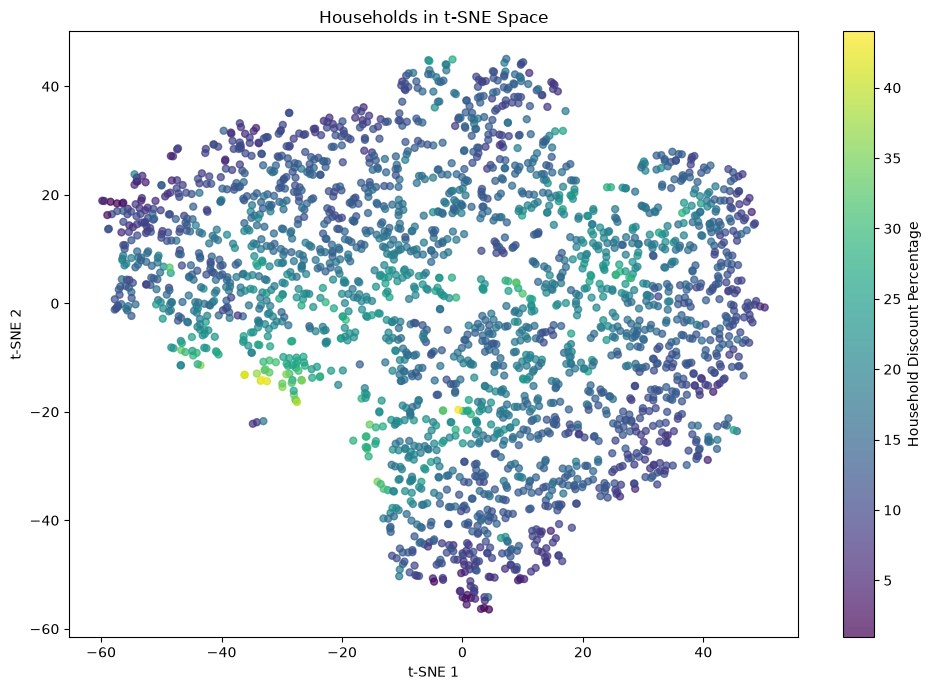

In [25]:
# Plot households in t-SNE space
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    household_tsne_results["TSNE1"],
    household_tsne_results["TSNE2"],
    c=household_features["discount_percentage"],
    cmap="viridis",
    alpha=0.7,
    s=25
)

plt.colorbar(scatter, label="Household Discount Percentage")
plt.title("Households in t-SNE Space")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

#### Save t-SNE Outputs

Save the two-dimensional t-SNE coordinates for all households so they can be reused for comparison and visualisation in later notebooks.

In [26]:
# Save t-SNE household coordinates
household_tsne_results.to_csv(
    os.path.join(pca_output_dir, "household_tsne_features.csv"),
    index=True
)

print("t-SNE output saved successfully.")
print(
    "Saved file:",
    os.path.join(pca_output_dir, "household_tsne_features.csv")
)

t-SNE output saved successfully.
Saved file: ../data/processed/dimensionality_reduction/household_tsne_features.csv


#### Final Output Validation

Verify that all six expected output files exist and that the saved household representations contain 2,500 households.

In [27]:
# Verify saved outputs
expected_files = [
    "household_pca_features.csv",
    "pca_component_loadings.csv",
    "pca_explained_variance.csv",
    "pca_reconstruction_errors.csv",
    "pca_transformation_decisions.csv",
    "household_tsne_features.csv"
]

for file in expected_files:
    file_path = os.path.join(pca_output_dir, file)
    print(f"{file}: {'Exists' if os.path.exists(file_path) else 'Missing'}")

print("\nPCA shape:", household_pca_reduced.shape)
print("t-SNE shape:", household_tsne_results.shape)

household_pca_features.csv: Exists
pca_component_loadings.csv: Exists
pca_explained_variance.csv: Exists
pca_reconstruction_errors.csv: Exists
pca_transformation_decisions.csv: Exists
household_tsne_features.csv: Exists

PCA shape: (2500, 6)
t-SNE shape: (2500, 2)


#### Save Original Standardized Household Features

Save the original standardized household-level features separately from the PCA-transformed features. This allows Notebook 07 to compare clustering results using both representations without repeating preprocessing.

In [28]:
# Save original standardized household features
household_features_scaled.to_csv(
    os.path.join(pca_output_dir, "household_features_scaled.csv"),
    index=True
)

print("Standardized household features saved.")
print("Shape:", household_features_scaled.shape)

Standardized household features saved.
Shape: (2500, 14)


In [29]:

import joblib
from pathlib import Path

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

models_dir = project_root / "models"
models_dir.mkdir(exist_ok=True)

joblib.dump(scaler, models_dir / "standard_scaler.joblib")
joblib.dump(pca, models_dir / "pca_model.joblib")

print("PCA and scaler saved!")


PCA and scaler saved!
